### 사전에 구현된 모델
#### ImageNet-1000(1k)
: 딥러닝 모델의 이미지 분류 학습에 사용되는 대규모 이미지 데이터 셋<br>
&nbsp;&nbsp;강아지, 고양이, 자동차, 새, 비행기, 과일 등 다양한 종류의 이미지가 있음
- 클래스 수: 1000개
- 학습이미지: 약 128만 장
- 이미지 크기: 다양한 크기

In [ ]:
%pip install torchinfo

In [35]:
import torch
from torch import nn
import torch.nn.functional as F
from torchvision import models, transforms
import matplotlib.pyplot as plt
from torchinfo import summary

In [ ]:
w=models.ResNet50_Weights.IMAGENET1K_V2
lm=models.resnet50(weights=w)
print(lm)

In [37]:
lm.eval()
with torch.no_grad():
    print(lm(torch.randn(2, 3, 224, 224)).shape)

torch.Size([2, 1000])


In [ ]:
summary(lm, input_size=(2, 3, 224, 224))

In [39]:
tr = transforms.Compose(
    [
        transforms.ToTensor(),
        transforms.Resize(size=(256)),
        transforms.CenterCrop(size=(224, 224)),
    ]
)

In [40]:
print(w.meta.keys())

dict_keys(['min_size', 'categories', 'num_params', 'recipe', '_metrics', '_ops', '_file_size', '_docs'])


In [ ]:
il=dict(enumerate(w.meta['categories']))
print(il)

In [42]:
il[30]

'bullfrog'

In [ ]:
%pip install imageio

In [ ]:
import imageio.v2 as imgio

x = imgio.imread(
    "https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcRit5iGifnmolOdSxcOonBSz_t4yWBM51lc-inNE-vNLk-10JKGZW8Szs1r&s=10"
)
print(type(x))
print(x.shape)
plt.imshow(x)
x = tr(x)
print(type(x))
print(x.shape)
plt.figure()
plt.imshow(x.permute(1, 2, 0))
x=x.unsqueeze(dim=0)
print(x.shape)

In [ ]:
lm.eval()
with torch.no_grad():
    yhs = lm(x).sort(descending=True)
    pet5 = F.softmax(yhs[0], dim=1)[0, :5] * 100
    print(pet5)
    prt5 = yhs[1][0, :5]
    print(prt5)
for i, j in enumerate(prt5):
    print(f"{il[j.item()]} ({round(pet5[i].item(),1)}%)")

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.019756326..1.0000002].


Text(0.5, 1.0, 'comic book (24.4%)')

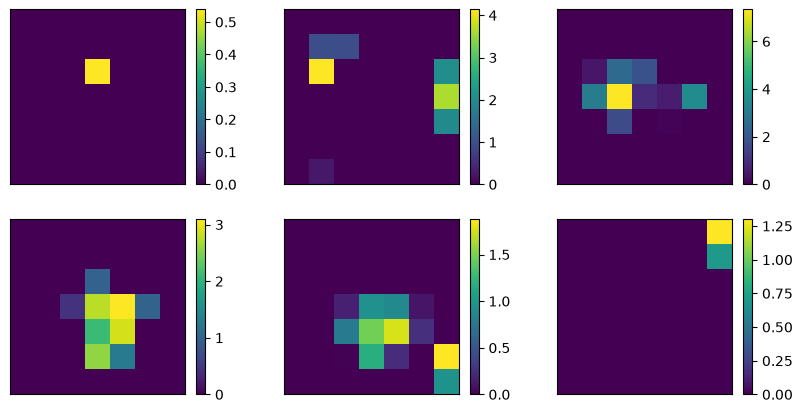

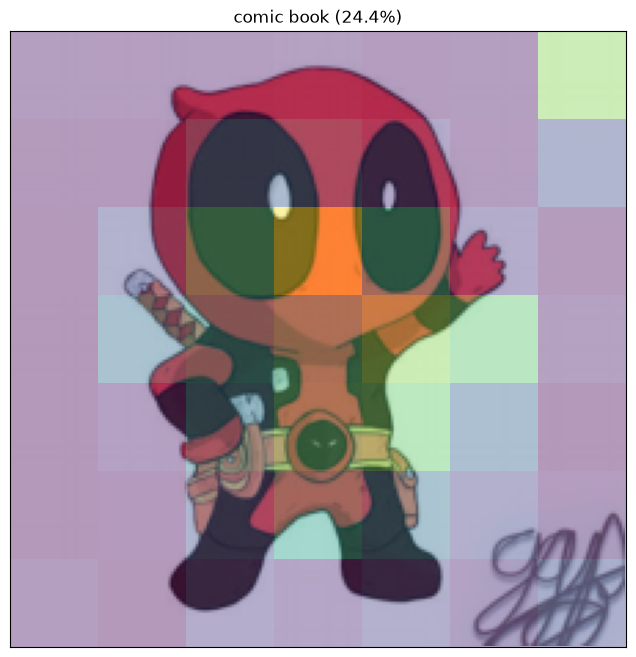

In [46]:
lm.eval()
f = nn.Sequential(*list(lm.children())[:-2])
with torch.no_grad():
    xf = f(x)
plt.figure(figsize=(10, 5))
for i in range(6):
    plt.subplot(2, 3, i + 1, xticks=[], yticks=[])
    plt.imshow(xf[0, i])
    plt.colorbar()
summ = xf.sum(dim=1)
plt.figure(figsize=(8, 8))
plt.xticks([])
plt.yticks([])
plt.imshow(x[0].permute(1, 2, 0))
plt.imshow(summ[0], extent=[0, 224, 224, 0], alpha=0.4)
prc = il[prt5[0].item()]
plt.title(f"{prc} ({round(pet5[0].item(),1)}%)")